## Grafos y comunidades: Solapadas

- **BigCLAM:** cada proveedor tiene una afiliación no negativa $F_u \in \mathbb{R}_{\geq 0}^K$ a K comunidades

- Dos proveedores compiten con probabilidad

$$P(u, v) = 1 - \exp\left(-F_u \cdot F_v\right), \qquad F_u \cdot F_v = \sum_c F_{uc} F_{vc}$$

- Un proveedor puede estar en varias comunidades

- K se elige con el AUC de aristas retenidas y el umbral δ con la regla teórica de Yang & Leskovec

- Gradiente solo usa la matriz dispersa del núcleo; el modelo es para aristas **sin peso**

### Constantes

- `RANGO_K`: número de comunidades que se prueban

- `FRAC_TEST`: fracción de aristas retenidas para el AUC

- `TOL_AUC`: se toma el K más chico a esta distancia del mejor AUC

- `RANGO_FACTOR`: múltiplos del δ teórico que se prueban

- `COB_MIN`: fracción mínima de nodos con ≥ 1 comunidad

- `ITER`, `TOL`: corte del ascenso de gradiente

In [1]:
RANGO_K = [5, 10, 20, 30, 40, 50, 60, 80, 100, 120, 150]
FRAC_TEST = 0.10
TOL_AUC = 0.005
RANGO_FACTOR = [0.25, 0.5, 1, 2, 4, 8]
ITER, TOL, MIN_ITER = 500, 1e-6, 50

### Teórico

**AUC de aristas retenidas** (elige K)

- Se ajusta con el 90% de las aristas; el 10% escondido son los **positivos** y otros tantos pares sin arista, los **negativos**

- Puntaje de un par: $s(u, v) = F_u \cdot F_v$

$$AUC = P\big(s_{pos} > s_{neg}\big)$$

- 0.5 = azar, 1 = perfecto


### Utilidades

In [2]:
NOTEBOOK = "c_solapadas"
%run ../funciones.ipynb
%run funciones.ipynb

In [3]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


### Carga

In [4]:
config = leer_config()
n = config["n"]
v = pd.read_parquet(datos_dir / "nodos.parquet").sort_values("idx", ignore_index=True)
a = pd.read_parquet(datos_dir / "aristas.parquet")
A = matriz(a, n, config["peso"])
Ab = matriz(a, n, "binario")
lab_pr = pd.read_parquet(datos_dir / "particion.parquet").sort_values("idx")[config["principal"]].to_numpy()
print(f"núcleo: {n:,} nodos | {Ab.nnz // 2:,} aristas | partición principal: {config['principal']}")

núcleo: 7,114 nodos | 40,957 aristas | partición principal: louvain


---
### **1. Elección de K (AUC)**

- Se retira el 10% de las aristas, se ajusta con el resto

- Se mide si $F_u \cdot F_v$ ordena las aristas retiradas por encima de pares al azar sin arista (AUC 0.5 = azar)

In [ ]:
entren, pos, neg = separar_aristas(Ab, FRAC_TEST)

grado_tr = np.asarray(entren.sum(axis=1)).ravel()
puntaje_grado = lambda pares: grado_tr[pares[:, 0]] * grado_tr[pares[:, 1]]
AUC_PISO = auc(puntaje_grado(pos), puntaje_grado(neg))
print(f"AUC del modelo de referencia (producto de grados): {AUC_PISO:.3f}")

ruido = lambda K: np.random.default_rng(SEED).uniform(0, .01, (n, K))
filas = []
for K in RANGO_K:
    t0 = time.time()
    F, hist = bigclam(entren, K, ITER, TOL, F0=semillas_bigclam(entren, K) + ruido(K), min_iter=MIN_ITER)
    seg = time.time() - t0
    it = len(hist) - 1
    filas.append({"K": K, "auc": auc(puntaje(F, pos), puntaje(F, neg)), "auc_piso": AUC_PISO,
                  "loglik": hist[-1], "iteraciones": it, "convergio": it < ITER,
                  "seg": seg, "columnas_vacias": int((F.max(0) < 1e-6).sum())})
    print(f"K = {K}: AUC {filas[-1]['auc']:.3f} (piso {AUC_PISO:.3f}) | {it} iteraciones en {seg:.0f} s", flush=True)
sel_k = pd.DataFrame(filas)
sel_k["supera_piso"] = sel_k.auc > sel_k.auc_piso

validos = sel_k[sel_k.supera_piso]
if validos.empty:
    print("⚠ ningún K supera al modelo de grados: BigCLAM no captura comunidades más allá del grado")
    validos = sel_k
K_BIGCLAM = int(validos[validos.auc >= validos.auc.max() - TOL_AUC].K.min())
print(f"K elegido = {K_BIGCLAM}")
sel_k.round(4)

AUC del modelo de referencia (producto de grados): 0.870


K = 5: AUC 0.892 (piso 0.870) | 88 iteraciones en 0 s


K = 10: AUC 0.903 (piso 0.870) | 53 iteraciones en 1 s


K = 20: AUC 0.910 (piso 0.870) | 58 iteraciones en 1 s


K = 30: AUC 0.952 (piso 0.870) | 97 iteraciones en 2 s


K = 40: AUC 0.930 (piso 0.870) | 91 iteraciones en 2 s


... (4 outputs left out)

K = 120: AUC 0.970 (piso 0.870) | 74 iteraciones en 4 s


K = 150: AUC 0.973 (piso 0.870) | 129 iteraciones en 9 s


K elegido = 100


,K,auc,auc_piso,loglik,iteraciones,convergio,seg,columnas_vacias,supera_piso
0,5,0.8921,0.87,-218447.3279,88,True,0.4783,0,True
1,10,0.9025,0.87,-210724.9670,53,True,0.7541,0,True
2,20,0.9095,0.87,-209767.4358,58,True,1.0546,0,True
3,30,0.9525,0.87,-176062.8012,97,True,2.0622,0,True
4,40,0.9305,0.87,-201047.7742,91,True,2.3424,0,True
5,50,0.9446,0.87,-190669.9857,72,True,2.2927,0,True
6,60,0.9324,0.87,-199738.8644,80,True,2.8177,0,True
7,80,0.9668,0.87,-151833.1387,71,True,3.0989,0,True
8,100,0.9711,0.87,-113910.6856,95,True,4.8217,0,True
9,120,0.9700,0.87,-122138.3333,74,True,4.4362,0,True


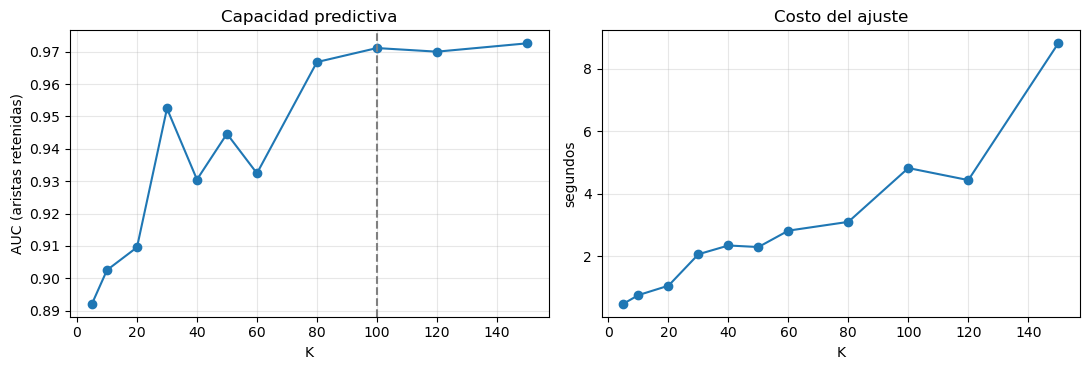

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(sel_k.K, sel_k.auc, "o-"); ax[0].axvline(K_BIGCLAM, ls="--", c="gray")
ax[0].set(xlabel="K", ylabel="AUC (aristas retenidas)", title="Capacidad predictiva")
ax[1].plot(sel_k.K, sel_k.seg, "o-"); ax[1].set(xlabel="K", ylabel="segundos", title="Costo del ajuste")
mostrar_fig("bigclam_k")

- **Todos los K superan al piso** (producto de grados, AUC **0.870**): las comunidades predicen aristas

- **El AUC sube hasta K = 80 y se aplana** (0.967–0.973 entre 80 y 150)

- **K elegido = 100** (AUC **0.971**), el más chico a 0.005 del mejor

---
### **2. Ajuste final y umbral δ**

- Se ajusta con todas las aristas; el nodo u está en la comunidad c si

$$F_{uc} \geq \delta$$

- δ teórico, con ε = densidad del núcleo:

$$\delta = \sqrt{-\log(1 - \varepsilon)}, \qquad \varepsilon = \frac{2m}{n(n-1)}$$

In [ ]:
t0 = time.time()
F, hist = bigclam(Ab, K_BIGCLAM, ITER, TOL, F0=semillas_bigclam(Ab, K_BIGCLAM) + ruido(K_BIGCLAM), min_iter=MIN_ITER)
seg_bc = time.time() - t0
it = len(hist) - 1

m_b = Ab.nnz // 2
EPS_FONDO = 2 * m_b / (n * (n - 1))
DELTA = float(np.sqrt(-np.log(1 - EPS_FONDO)))
d0 = DELTA
M = F >= DELTA

v["n_comunidades"] = M.sum(1)
v["dominante"] = np.where(F.max(1) > 0, F.argmax(1), -1)
v["afiliacion_max"] = F.max(1)


deg = np.asarray(A.sum(axis=1)).ravel()
filas = []
for f_ in RANGO_FACTOR:
    M_f = F >= f_ * d0
    tam = M_f.sum(0)
    conds = [conductancia_conjunto(A, np.flatnonzero(M_f[:, c]), deg) for c in range(K_BIGCLAM) if tam[c] >= MIN_TAM]
    filas.append({"factor": f_, "delta": f_ * d0, "cobertura": (M_f.sum(1) > 0).mean(), "membresias_media": M_f.sum(1).mean(),
                  "pct_solapados": 100 * (M_f.sum(1) >= 2).mean(), "comunidades_grandes": len(conds),
                  "conductancia_med": np.median(conds) if conds else np.nan})
sel_d = pd.DataFrame(filas)
sel_d["elegido"] = np.isclose(sel_d.factor, 1.0)

print(f"{it} iteraciones en {seg_bc:.0f} s ({'convergió' if it < ITER else 'tope de ITER'}) | "
      f"ε = {EPS_FONDO:.5f} → δ = {DELTA:.4f}")
print(f"con δ: cobertura {(M.sum(1) > 0).mean():.1%} | solapados {(M.sum(1) >= 2).mean():.1%} | "
      f"con comunidad dominante {(v.dominante >= 0).mean():.1%} de {n:,} nodos")
sel_d.round(4)

50 iteraciones en 3 s (convergió) | ε = 0.00162 → δ = 0.0403
con δ: cobertura 71.9% | solapados 10.0% | con comunidad dominante 100.0% de 7,114 nodos


,factor,delta,cobertura,membresias_media,pct_solapados,comunidades_grandes,conductancia_med,elegido
0,0.25,0.0101,0.9315,6.0786,27.1155,100,0.5180,False
1,0.50,0.0201,0.8344,3.0876,17.0931,100,0.6372,False
2,1.00,0.0403,0.7187,1.3073,9.9944,100,0.8016,True
3,2.00,0.0805,0.5662,0.6950,4.5825,89,0.9228,False
4,4.00,0.1610,0.4681,0.4952,2.3053,41,0.2587,False
5,8.00,0.3220,0.4022,0.4176,1.4478,41,0.1911,False


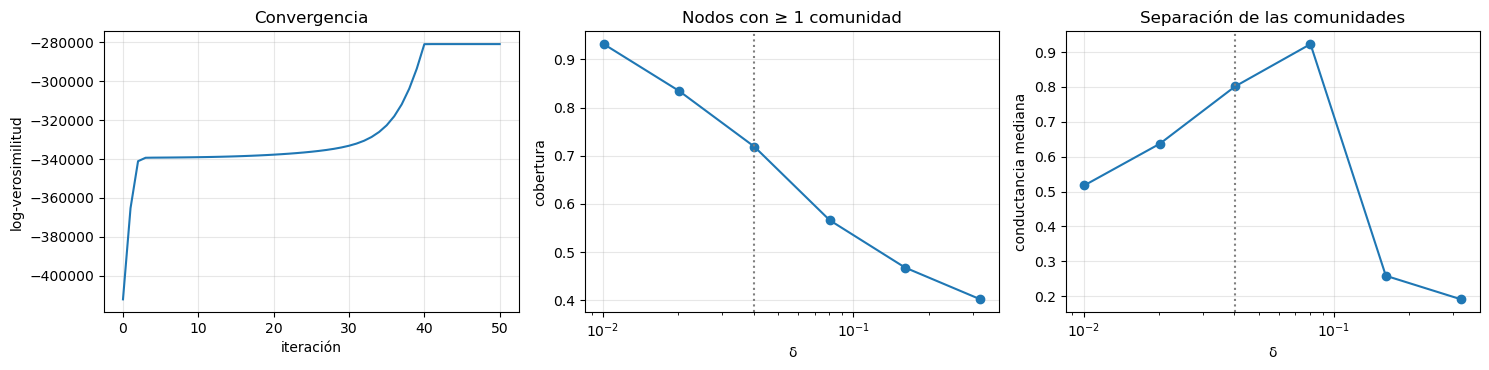

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(hist); ax[0].set(xlabel="iteración", ylabel="log-verosimilitud", title="Convergencia")
ax[1].semilogx(sel_d.delta, sel_d.cobertura, "o-")
ax[1].set(xlabel="δ", ylabel="cobertura", title="Nodos con ≥ 1 comunidad")
ax[2].semilogx(sel_d.delta, sel_d.conductancia_med, "o-")
ax[2].set(xlabel="δ", ylabel="conductancia mediana", title="Separación de las comunidades")
for ax_ in ax[1:]:
    ax_.axvline(DELTA, ls=":", c="gray")
mostrar_fig("bigclam_delta")

- **Convergencia** en **50** iteraciones (3s); la log-verosimilitud sube monótona

- **δ bajo:** cada proveedor queda en muchas comunidades (6.1 en media con 0.25×) y la conductancia sube

- **δ alto:** se pierde cobertura (40% con 8×) y se apagan comunidades (100 → 41 grandes)

- **δ elegido = 0.040** (el teórico, ε = densidad 0.0016): cobertura **71.9%**, **10.0%** solapados; 

- Conductancia mediana alta (**0.80**): las comunidades de BigCLAM son más porosas que las de Louvain

---
### **3. Solapamiento**

,proveedores,grado_med,pct_consorcio,regiones_med,cuota_region_med
grupo,,,,,
dos o más,711,315.0,1.125,18.0,0.448
sin comunidad,2001,141.0,0.650,9.0,0.591
una,4402,154.0,0.454,10.0,0.598


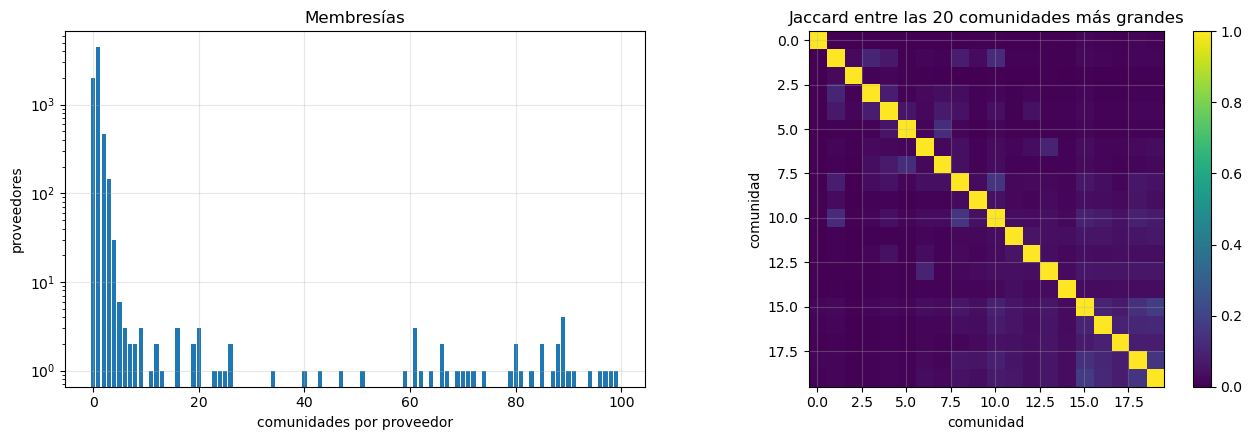

Jaccard fuera de la diagonal: máximo 0.18, mediana 0.019


In [ ]:
nm = M.sum(1)

tam_bc = M.sum(0)
solap = (v.assign(grupo=np.select([nm == 0, nm == 1], ["sin comunidad", "una"], "dos o más"))
           .groupby("grupo").agg(proveedores=("idx", "size"), grado_med=("grado_completo", "median"),
                                pct_consorcio=("es_consorcio", pct_si), regiones_med=("n_regiones", "median"),
                                cuota_region_med=("cuota_region_dom", "median")).round(3))
display(solap)

top = np.argsort(-tam_bc)[:TOP_K]
Mt = M[:, top].astype(float)
inter = Mt.T @ Mt
union = tam_bc[top][:, None] + tam_bc[top][None, :] - inter
jac = np.divide(inter, union, out=np.zeros_like(inter), where=union > 0)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].bar(*np.unique(nm, return_counts=True))
ax[0].set(xlabel="comunidades por proveedor", ylabel="proveedores", yscale="log", title="Membresías")
im = ax[1].imshow(jac, cmap="viridis", vmin=0, vmax=1); plt.colorbar(im, ax=ax[1])
ax[1].set(title=f"Jaccard entre las {len(top)} comunidades más grandes", xlabel="comunidad", ylabel="comunidad")
mostrar_fig("bigclam_solapamiento")
fuera = jac[~np.eye(len(top), dtype=bool)]
print(f"Jaccard fuera de la diagonal: máximo {fuera.max():.2f}, mediana {np.median(fuera):.3f}")

- **10.0%** de los proveedores (711) está en ≥ 2 comunidades

- Compiten en varios "mercados" a la vez; **28%** (2,001) no pasa δ en ninguna

- **Los solapados** tienen el doble de grado (**315** vs **154**) y participan en más regiones (**18** vs **10**)

- Con menos peso en su región principal (45% vs 60%)

- **Consorcios:** son el 0.6% del núcleo, demasiado pocos para concluir algo sobre ellos

- **Fuera de la diagonal** el Jaccard es bajo (máximo **0.18**, mediana 0.02): las comunidades comparten bordes

---
### **4. BigCLAM vs la partición principal**

- Para cada comunidad de BigCLAM, la comunidad de la partición con mayor Jaccard

- NMI y ARI entre la partición y la comunidad **dominante** (argmax F) de cada nodo

In [10]:
P = indicadora(lab_pr)
inter = (sp.csr_matrix(M.astype(float)).T @ P).toarray()
union = tam_bc[:, None] + np.asarray(P.sum(0)).ravel()[None, :] - inter
mejor = (inter / np.maximum(union, 1)).max(1)
grandes_bc = tam_bc >= MIN_TAM
con_dom = dom >= 0
vs_part = pd.DataFrame([
    {"medida": "Jaccard medio con la mejor comunidad de la partición", "valor": mejor[grandes_bc].mean()},
    {"medida": "comunidades BigCLAM con Jaccard ≥ 0.5", "valor": int((mejor[grandes_bc] >= .5).sum())},
    {"medida": "comunidades BigCLAM grandes", "valor": int(grandes_bc.sum())},
    {"medida": "NMI partición vs dominante", "valor": nmi(lab_pr[con_dom], dom[con_dom])},
    {"medida": "ARI partición vs dominante", "valor": ari(lab_pr[con_dom], dom[con_dom])},
    {"medida": "nodos comparados (con comunidad dominante)", "valor": int(con_dom.sum())},
    {"medida": "Q de la dominante como partición", "valor": modularidad(A[con_dom][:, con_dom], dom[con_dom])},
    {"medida": "Q de la partición principal", "valor": modularidad(A, lab_pr)}])

vs_part.round(3)

,medida,valor
0,Jaccard medio con la mejor comunidad de la partición,0.156
1,comunidades BigCLAM con Jaccard ≥ 0.5,7.000
2,comunidades BigCLAM grandes,100.000
3,NMI partición vs dominante,0.718
4,ARI partición vs dominante,0.557
5,nodos comparados (con comunidad dominante),7114.000
6,Q de la dominante como partición,0.754
7,Q de la partición principal,0.870


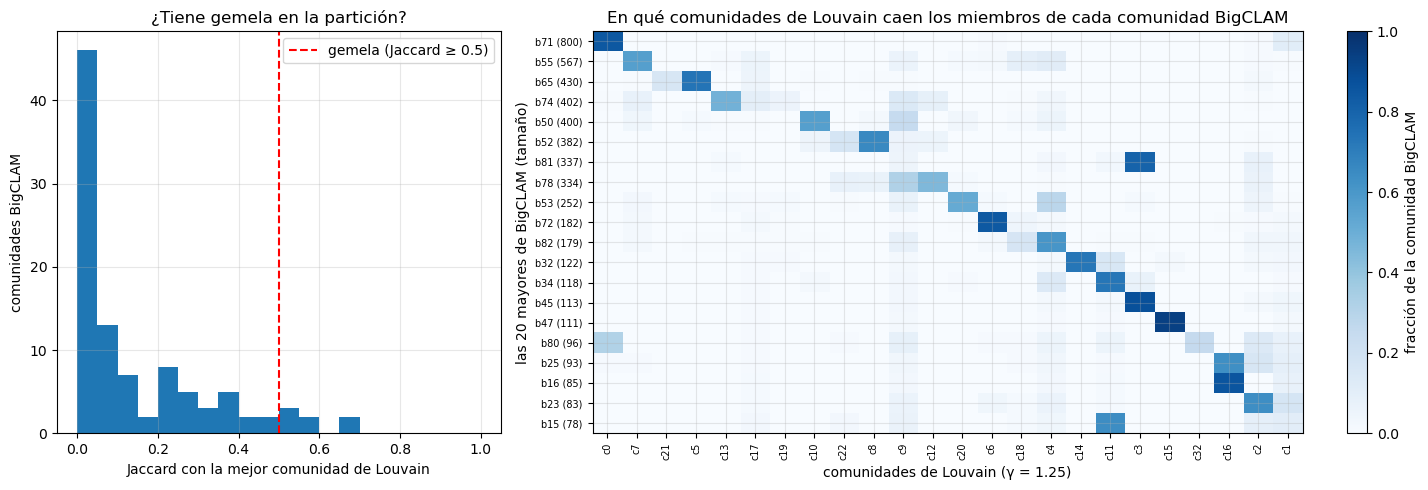

In [11]:
top_bc = np.argsort(-tam_bc)[:TOP_K]
frac = pd.DataFrame(inter[top_bc] / tam_bc[top_bc, None], index=top_bc)    # fracción de cada comunidad BigCLAM en cada una de Louvain
frac = frac.loc[:, frac.max() > .05]
orden = frac.idxmax(axis=0).map({r: k for k, r in enumerate(frac.index)}).sort_values().index
frac = frac[orden]
fig, ax = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 2]})
ax[0].hist(mejor[grandes_bc], bins=20, range=(0, 1))
ax[0].axvline(.5, ls="--", c="red", label="gemela (Jaccard ≥ 0.5)")
ax[0].set(xlabel="Jaccard con la mejor comunidad de Louvain", ylabel="comunidades BigCLAM", title="¿Tiene gemela en la partición?")
ax[0].legend()
im = ax[1].imshow(frac.to_numpy(), aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax[1].set_yticks(range(len(frac))); ax[1].set_yticklabels([f"b{c} ({tam_bc[c]})" for c in frac.index], fontsize=7)
ax[1].set_xticks(range(frac.shape[1])); ax[1].set_xticklabels([f"c{c}" for c in frac.columns], fontsize=7, rotation=90)
ax[1].set(xlabel=f"comunidades de Louvain (γ = {config['gamma']})", ylabel=f"las {TOP_K} mayores de BigCLAM (tamaño)",
          title="En qué comunidades de Louvain caen los miembros de cada comunidad BigCLAM")
plt.colorbar(im, ax=ax[1], label="fracción de la comunidad BigCLAM")
mostrar_fig("bigclam_vs_particion")

- **Solo 7 de las 100** comunidades de BigCLAM tienen una "gemela" en la partición (Jaccard ≥ 0.5; medio 0.16)

- BigCLAM corta más fino (100 vs 41) y sus comunidades se superponen, así que rara vez calzan una a una

- **No contradicen:** las 20 mayores de BigCLAM caen en su mayoría (50–95%) dentro de **una sola** comunidad de Louvain

- El Jaccard es bajo por tamaño, porque cada comunidad de BigCLAM suele ser un **subconjunto** de una de Louvain

- **A nivel de nodo sí coinciden:** NMI **0.72** (ARI 0.56) entre la partición y la comunidad dominante

- Q es menor (**0.754** vs **0.870**) porque BigCLAM no optimiza modularidad, modela solapamiento

---
### **5. Exportación a `temp/datos/`**

- `membresias.parquet`: (idx, comunidad, afiliación) para F_uc ≥ δ

- `bigclam.parquet`: idx, número de comunidades y comunidad dominante

- `bigclam_delta_web`: tamaño de cada comunidad para cada δ

In [12]:
u, c = np.nonzero(M)
pd.DataFrame({"idx": u, "comunidad": c, "afiliacion": F[u, c]}).to_parquet(datos_dir / "membresias.parquet", index=False)
v[["idx", "n_comunidades", "dominante", "afiliacion_max"]].to_parquet(datos_dir / "bigclam.parquet", index=False)
config.update({"k_bigclam": K_BIGCLAM, "delta": DELTA, "delta_teorico": d0, "eps_fondo": EPS_FONDO,
               "delta_regla": "teórico Yang & Leskovec: sqrt(-log(1 - ε)), ε = densidad",
               "iteraciones_bigclam": it, "bigclam_convergio": bool(it < ITER),
               "cobertura_delta": float((M.sum(1) > 0).mean())})
guardar_config(config)
web = pd.concat([pd.DataFrame({"factor": f_, "delta": f_ * d0, "comunidad": np.arange(K_BIGCLAM), "tamano": (F >= f_ * d0).sum(0)})
                 for f_ in RANGO_FACTOR], ignore_index=True)

---
### **6. Escritura de resultados**

In [13]:
escritos = guardar_tablas({"eleccion_k": sel_k, "eleccion_delta": sel_d, "solapamiento": solap.reset_index(),
                           "bigclam_vs_particion": vs_part,
                           "jaccard_top": pd.DataFrame(jac, columns=[f"c{x}" for x in top]).assign(comunidad=top),
                           "tiempos": pd.DataFrame([{"metodo": f"bigclam K={K_BIGCLAM}", "iteraciones": it, "seg": seg_bc}]),
                           "bigclam_delta_web": web})

Escrito en 05_Comunidad/temp/c_solapadas/: eleccion_k, eleccion_delta, solapamiento, bigclam_vs_particion, jaccard_top, tiempos, bigclam_delta_web


#### a. Verificación

In [14]:
verificar_salidas(escritos)
assert (F >= 0).all(), "F tiene valores negativos"
assert hist[-1] >= hist[0], "la log-verosimilitud no subió"
assert sel_k.auc.max() > 0.5, "BigCLAM no supera al azar"
print("F ≥ 0 | la log-verosimilitud sube | AUC > 0.5")

OK: 7 tablas (parquet + json) | 4 figuras: bigclam_delta, bigclam_k, bigclam_solapamiento, bigclam_vs_particion
F ≥ 0 | la log-verosimilitud sube | AUC > 0.5


---
### **7. Cerrar sesión**

In [15]:
spark.stop()